# CNN, BERT e encoders modernos

Nestor, Letícia e Gabriel · MAE5920. Este notebook lê experimentos reais já concluídos. Não treina nem baixa modelos. O estudo anterior de MLPs e o steering do Qwen continuam nos notebooks próprios.

In [1]:
from pathlib import Path
import json, sys, numpy as np, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'sequence_config.json').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from imdb_lab.common import read_json
B = ROOT / 'results/sequences'
s = read_json(B / 'summary.json')
v = read_json(B / 'verification.json')
assert v['status'] == 'passed'
print(v['training_runs'], 'treinos; auditoria de', v['audit_checkpoints'], 'checkpoints')

87 treinos; auditoria de 43 checkpoints


## Papéis dos dados

O mesmo prefixo de até 128 palavras entra em todos os modelos. A auditoria de 2.048 exemplos exclui todos os papéis da extensão MLP. O teste oficial não foi reaberto. A validação escolhe a taxa e a época, antes da auditoria.

In [2]:
m = read_json(B / 'data_manifest.json')
old = read_json(ROOT / 'results/didactic/data_manifest.json')
assert not set(m['roles']['audit']['ids']) & set().union(*(set(x['ids']) for x in old['roles'].values()))
display(pd.DataFrame([{'papel': k, 'n': r['n'], 'classe 0': r['label_counts']['0'], 'classe 1': r['label_counts']['1']} for k,r in m['roles'].items()]))

,papel,n,classe 0,classe 1
0,train,6144,3072,3072
1,validation,1536,768,768
2,audit,2048,1024,1024


## A CNN usada neste estudo

Embedding treinável 128, convoluções paralelas 3/4/5, cem filtros por janela, ReLU, max pooling com máscara, concatenação 300, dropout e saída linear binária. O vocabulário usa só o treino. A rede aprende embeddings e filtros do zero. A saída contém dois logits; o softmax os converte em probabilidades para leitura.

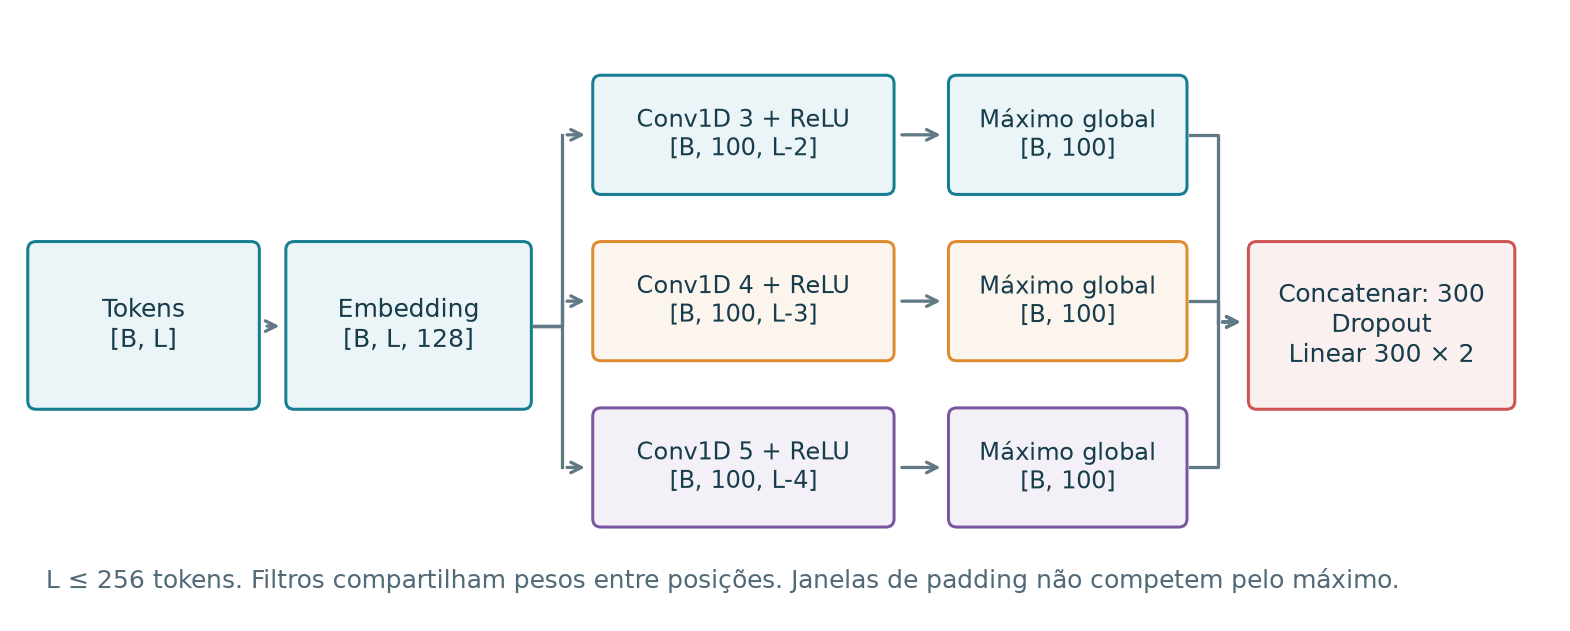

,label,parameters,lr,best_epochs
3,"3/4/5, 100 filtros",2714502,0.001,"[5, 6, 6]"
4,"Janela 3, 100 filtros",2598702,0.001,"[7, 7, 8]"
5,"Janela 5, 100 filtros",2624302,0.001,"[7, 6, 6]"
6,"3/4/5, 32 filtros",2609442,0.001,"[8, 7, 7]"


In [3]:
display(Image(filename=str(B / 'figures/cnn_diagram.png')))
rows = pd.DataFrame(s['groups'])
display(rows[rows.group.eq('cnn_architecture')][['label','parameters','lr','best_epochs']])

## Otimizador e taxa formam uma comparação

Os painéis mostram taxa comum e taxa escolhida entre três candidatas por método. Pesos e minibatches são pareados por semente. A linha representa a média e a faixa, mínimo e máximo das três sementes, sem interpretação de intervalo de confiança.

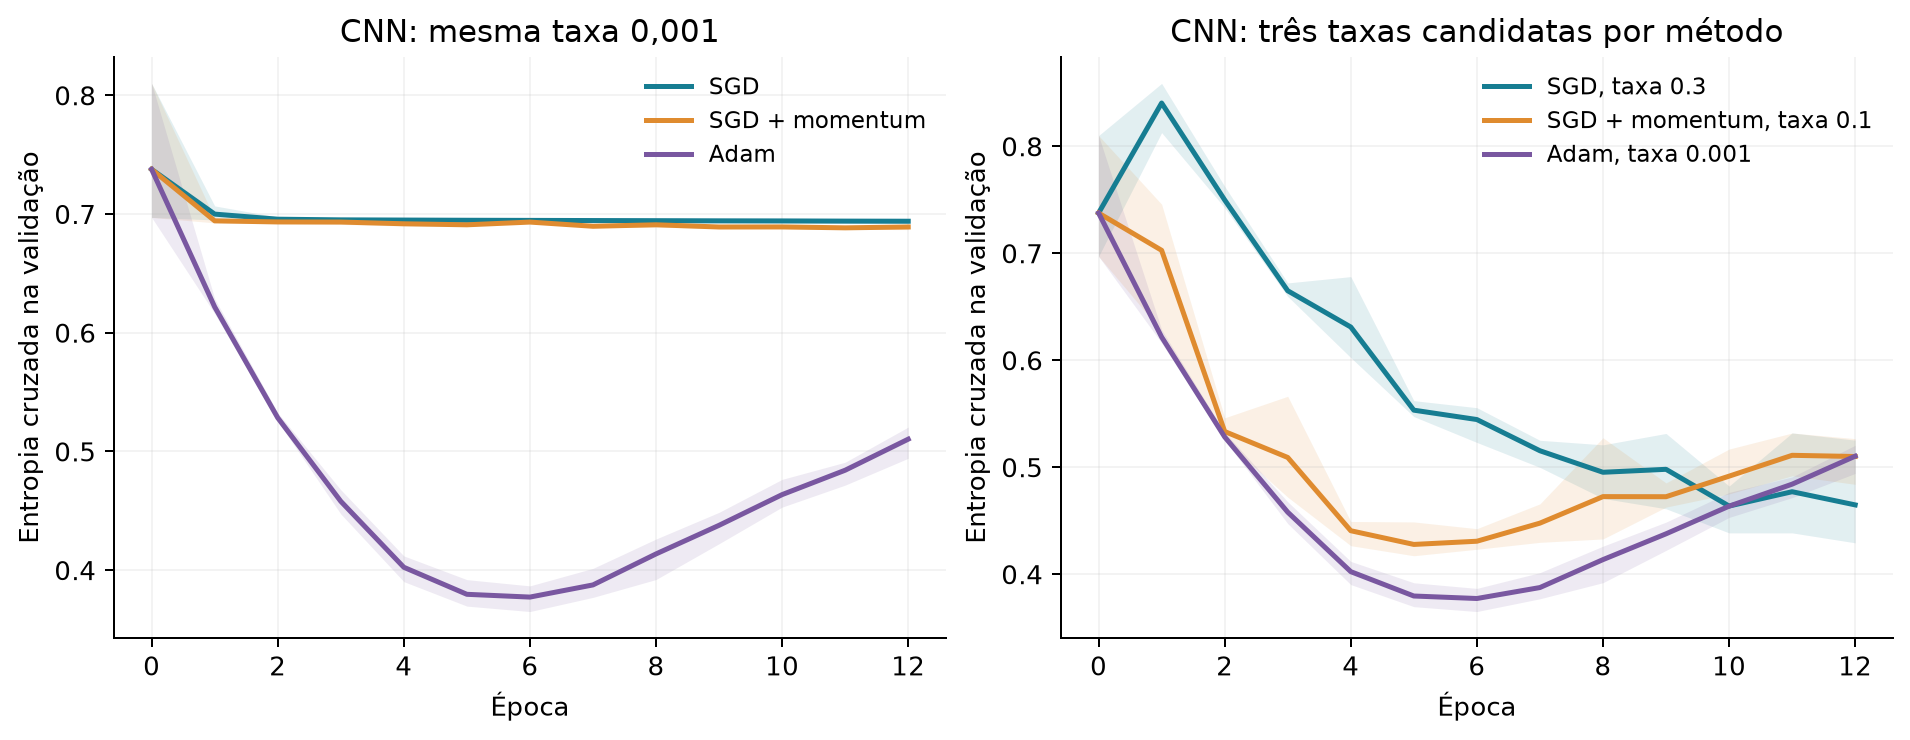

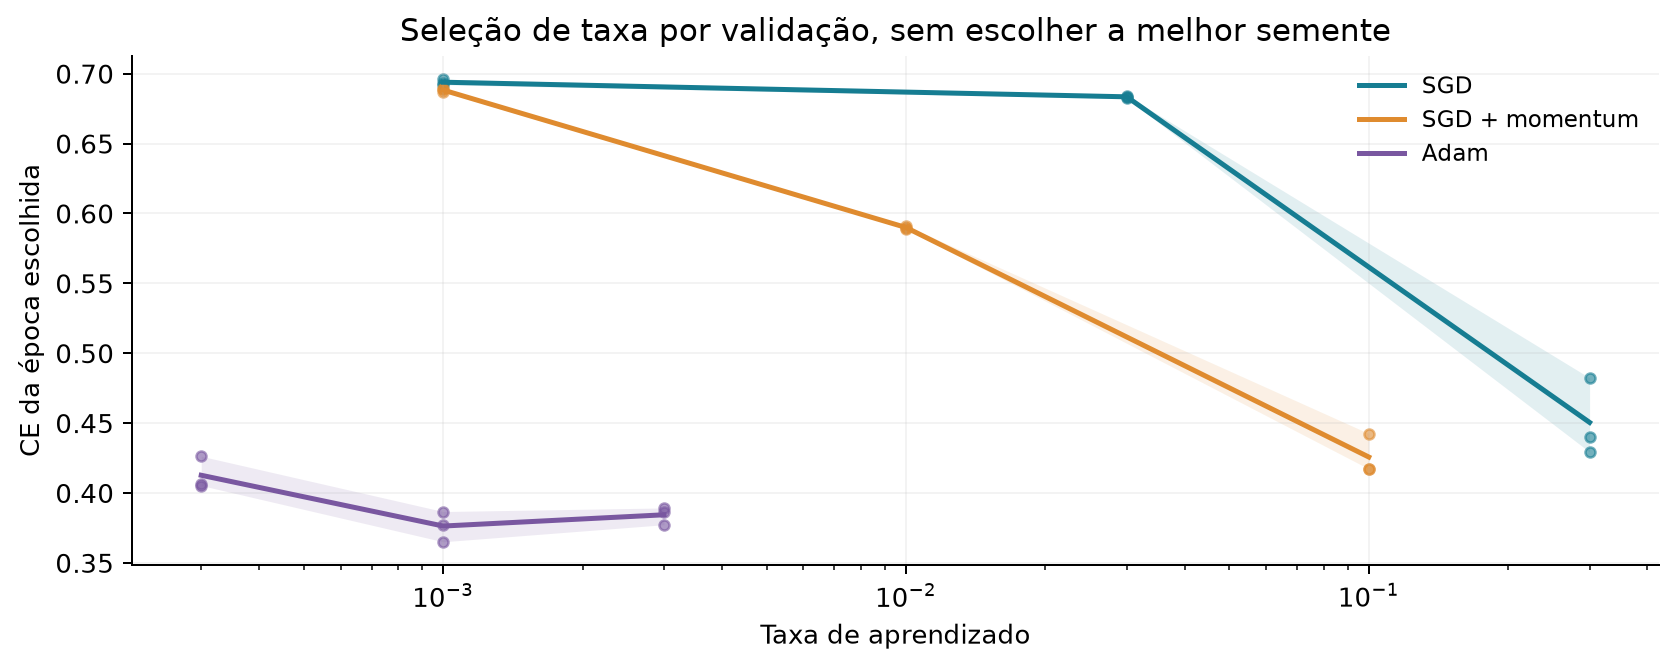

,label,lr,accuracy_mean,accuracy_min,accuracy_max,ce_mean
0,SGD,0.300,0.765299,0.745605,0.780762,0.479834
1,SGD + momentum,0.100,0.793457,0.786133,0.798828,0.469848
2,Adam,0.001,0.819499,0.817383,0.822754,0.409369


In [4]:
display(Image(filename=str(B / 'figures/cnn_optimizers.png')))
display(Image(filename=str(B / 'figures/cnn_learning_rates.png')))
display(rows[rows.group.eq('cnn_optimizer')][['label','lr','accuracy_mean','accuracy_min','accuracy_max','ce_mean']])

## Arquitetura e dropout

As variantes reutilizam a taxa de Adam escolhida para a CNN principal. Não há ajuste por variante. O total de parâmetros inclui o embedding; mudar o número de filtros afeta apenas parte da rede. A CE de treino é medida em avaliação, com dropout desligado.

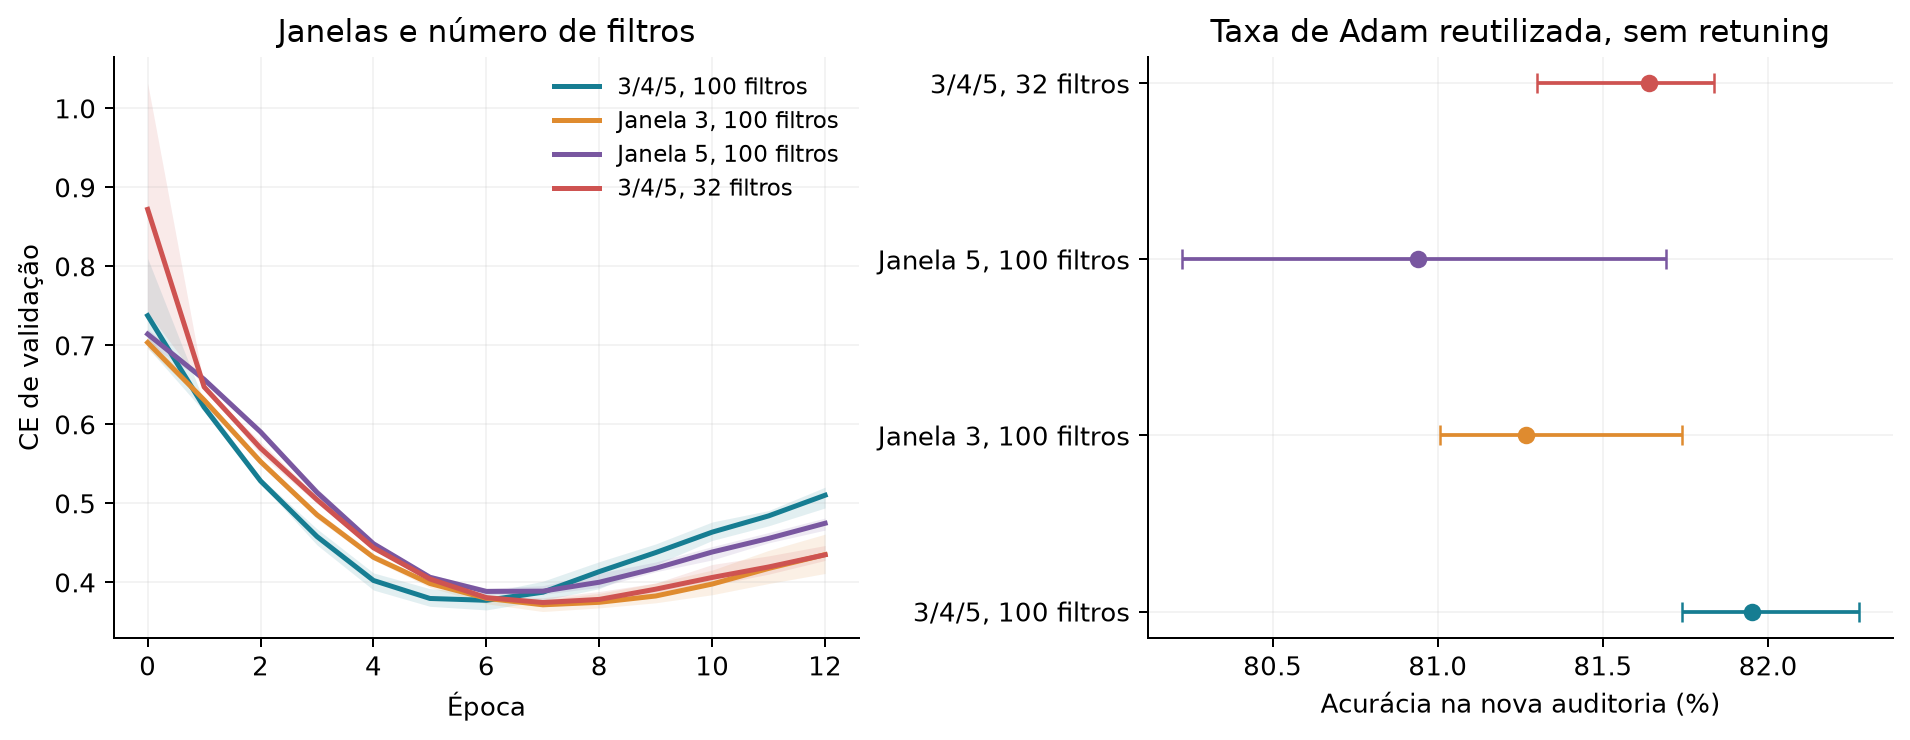

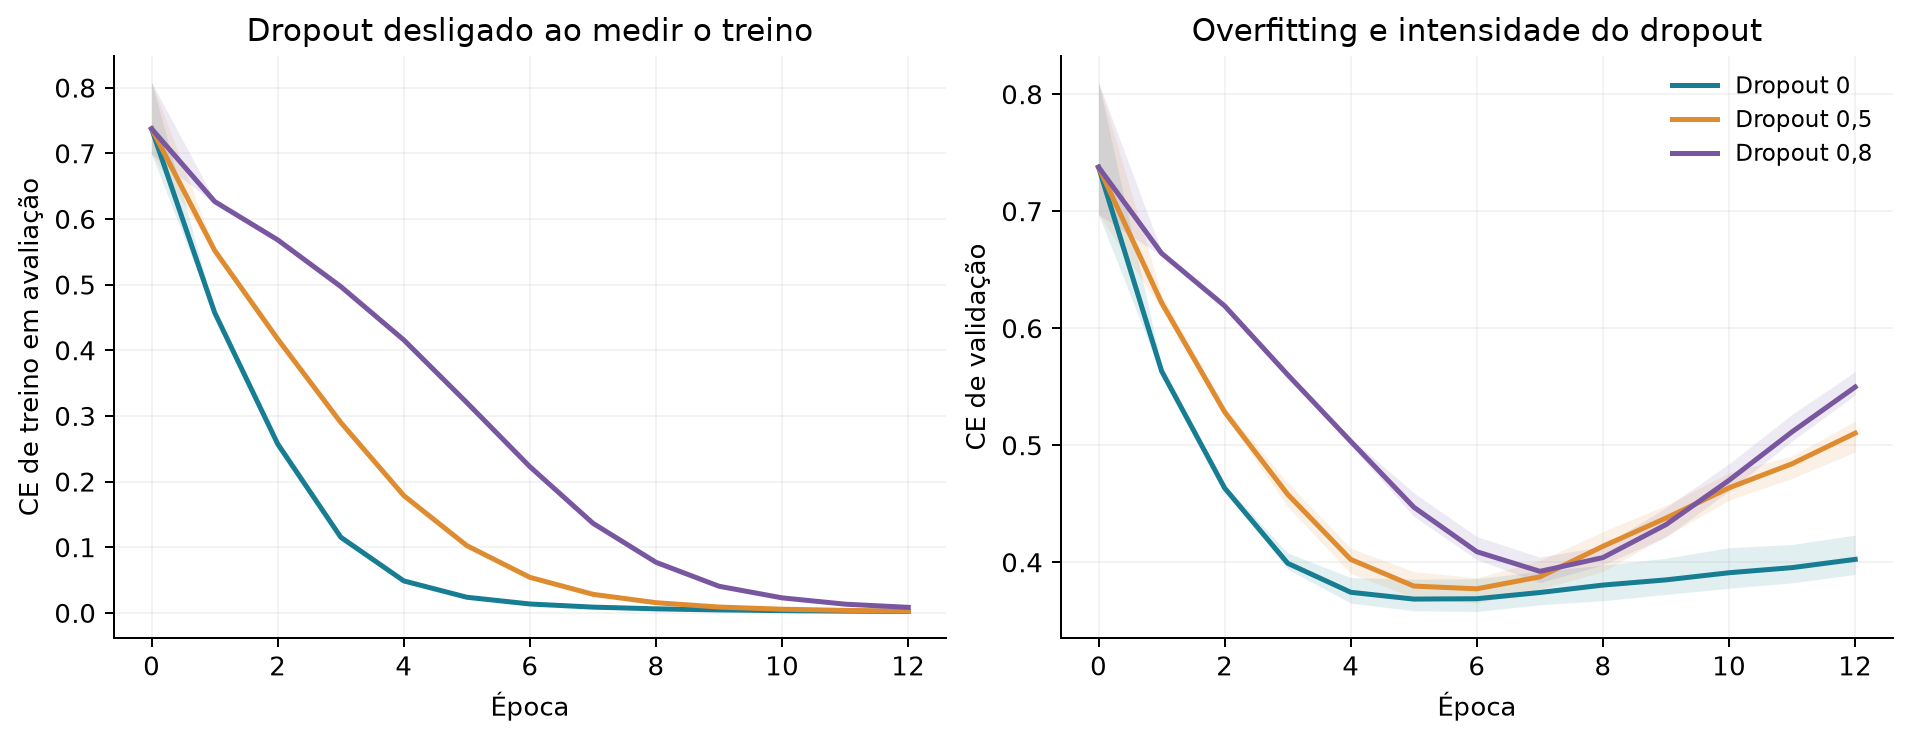

,label,best_epochs,validation_ce_mean,accuracy_mean,ce_mean
7,"Dropout 0,5","[5, 6, 6]",0.376362,0.819499,0.409369
8,Dropout 0,"[5, 6, 5]",0.368322,0.818034,0.411178
9,"Dropout 0,8","[7, 7, 7]",0.392240,0.804362,0.421658


In [5]:
display(Image(filename=str(B / 'figures/cnn_architectures.png')))
display(Image(filename=str(B / 'figures/cnn_dropout.png')))
display(rows[rows.group.eq('cnn_dropout')][['label','best_epochs','validation_ce_mean','accuracy_mean','ce_mean']])

## O que o encoder calcula

Cada token ganha uma representação contextual de 768 dimensões. Fazemos a média dos estados finais, excluindo padding e tokens especiais. BERT tem 12 blocos, DistilBERT 6 e ModernBERT-base 22. No ModernBERT, a atenção alterna janelas locais e blocos globais, com posições rotativas. A ordem das operações difere entre arquiteturas.

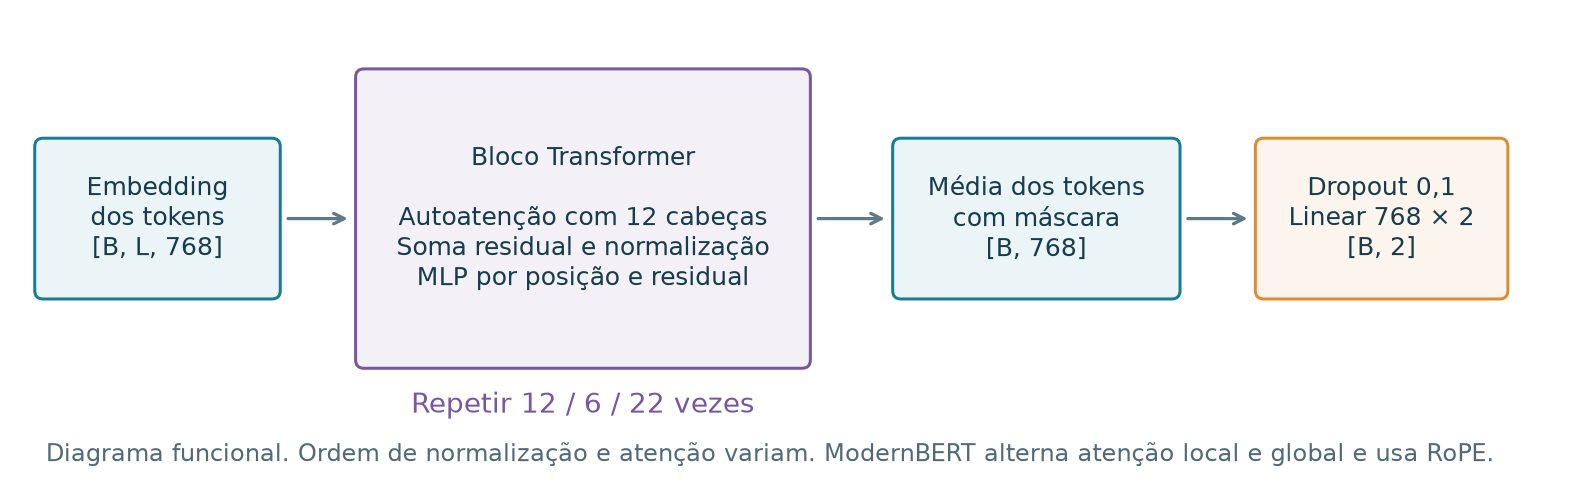

,num_hidden_layers,hidden_size,num_attention_heads,backbone_parameters,parameters
bert,12,768,12,108891648,108893186
distilbert,6,768,12,66362880,66364418
modernbert,22,768,12,149014272,149015810


Revisões fixadas: {'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'answerdotai/ModernBERT-base': '8949b909ec900327062f0ebf497f51aef5e6f0c8'}


In [6]:
display(Image(filename=str(B / 'figures/encoder_diagram.png')))
display(pd.DataFrame(s['encoder_architectures']).T[['num_hidden_layers','hidden_size','num_attention_heads','backbone_parameters','parameters']])
print('Revisões fixadas:', {k:r['revision'] for k,r in read_json(B / 'models_pinned.json').items()})

## Congelar e ajustar integralmente

O modo congelado treina apenas 1.538 parâmetros sobre vetores pré-computados. O ajuste completo usa gradientes em todas as camadas. As cabeças começam iguais para a mesma semente. As receitas têm otimizadores e orçamentos diferentes; não isolam destravar pesos como único fator. Encoder congelado fica em avaliação; no ajuste completo, o dropout do encoder funciona durante o treino.

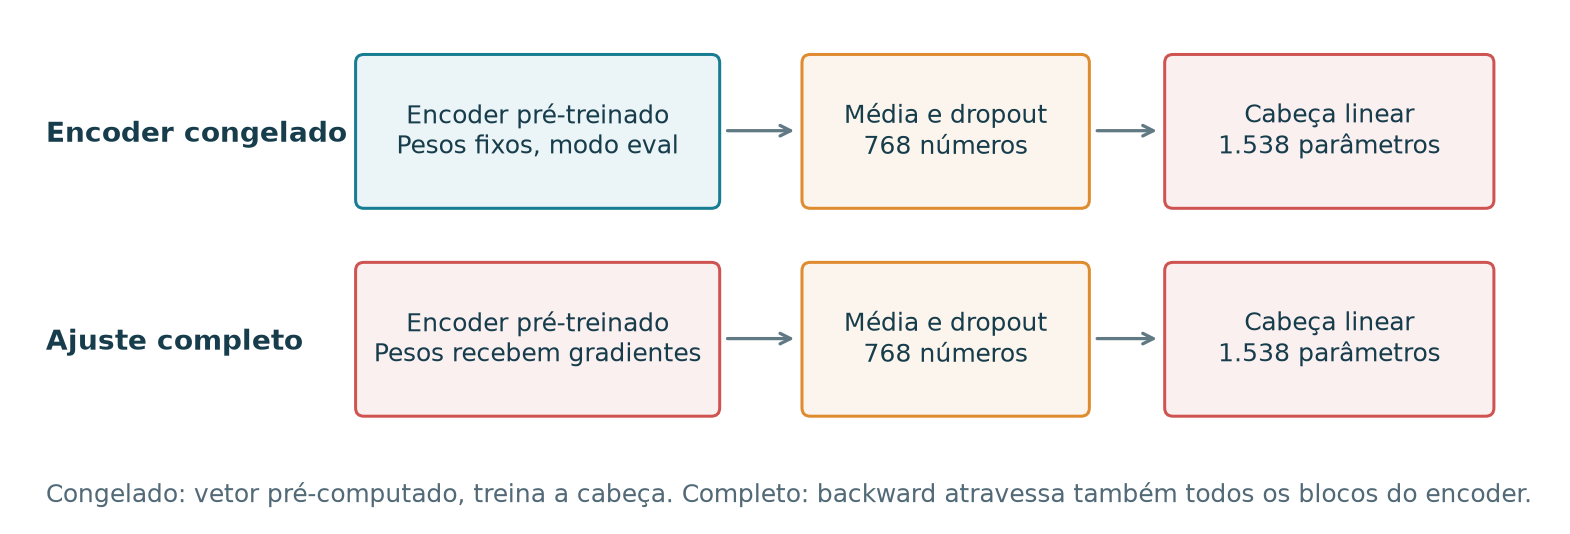

,regime,épocas,batch,taxas,otimizador
0,probe,40,128,"[0.001, 0.01, 0.1]",Adam
1,full,3,32,"[1e-05, 3e-05]",AdamW


In [7]:
display(Image(filename=str(B / 'figures/transfer_diagram.png')))
cfg = s['config']['encoders']
display(pd.DataFrame([{'regime': k, 'épocas': cfg[k]['epochs'], 'batch': cfg[k]['batch_size'], 'taxas': cfg[k]['learning_rates'], 'otimizador': cfg[k]['optimizer']} for k in ['probe','full']]))

## Resultados na nova auditoria interna

Os encoders usam os mesmos exemplos, prefixos e formato de cabeça linear neste estudo. Pré-treinamento, vocabulários, número de parâmetros e orçamentos diferem. Estes resultados não devem ser misturados com os números no teste oficial dos relatórios anteriores.

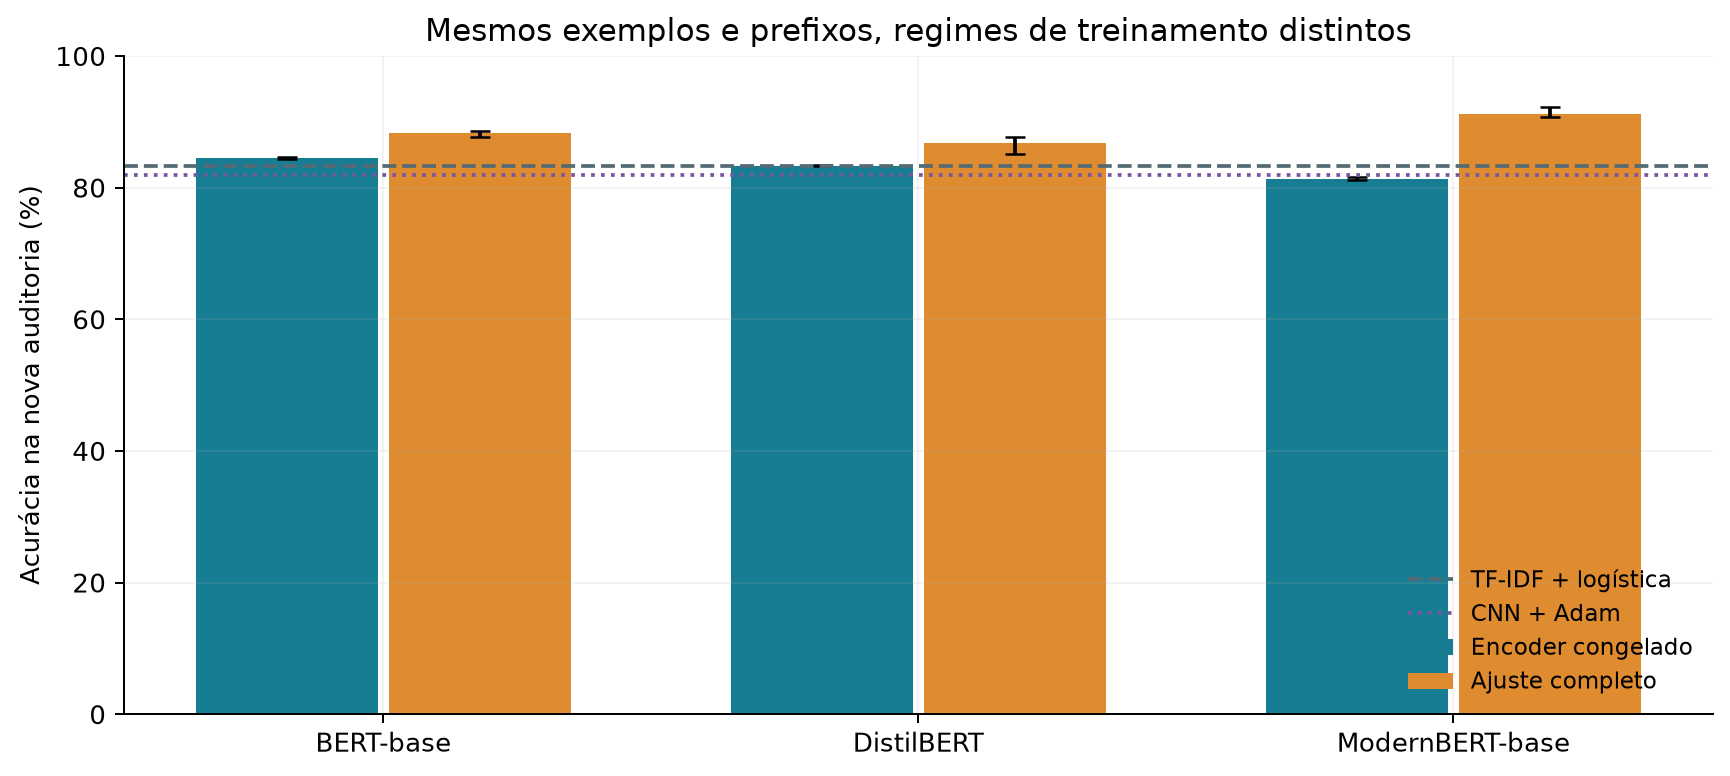

,label,trainable_parameters,lr,accuracy_mean,accuracy_min,accuracy_max,ce_mean,f1_macro_mean
10,BERT-base congelado,1538,0.01000,0.845215,0.844238,0.846191,0.365514,0.845095
11,BERT-base ajuste completo,108893186,0.00003,0.883138,0.876953,0.886719,0.302736,0.883090
12,DistilBERT congelado,1538,0.01000,0.833496,0.833008,0.833984,0.383870,0.833429
13,DistilBERT ajuste completo,66364418,0.00003,0.868001,0.851074,0.877441,0.338196,0.867815
14,ModernBERT-base congelado,1538,0.01000,0.812988,0.811035,0.815430,0.410333,0.812949
15,ModernBERT-base ajuste completo,149015810,0.00003,0.912435,0.907227,0.921875,0.245797,0.912408


TF-IDF: {'run_id': 'tfidf', 'ce': 0.3849398925344867, 'accuracy': 0.8330078125, 'f1_macro': 0.8330000085834699, 'brier': 0.12069978279155542, 'confusion_matrix': [[846, 178], [164, 860]]}


In [8]:
display(Image(filename=str(B / 'figures/encoder_comparison.png')))
display(rows[rows.group.eq('encoder')][['label','trainable_parameters','lr','accuracy_mean','accuracy_min','accuracy_max','ce_mean','f1_macro_mean']])
print('TF-IDF:', s['baseline'])

## Hiperparâmetros dos Transformers

Cada taxa é testada nas três sementes. A seleção minimiza a média da melhor CE de validação, sem selecionar a melhor semente. As três épocas do ajuste completo são um orçamento fixo, sem garantia de convergência.

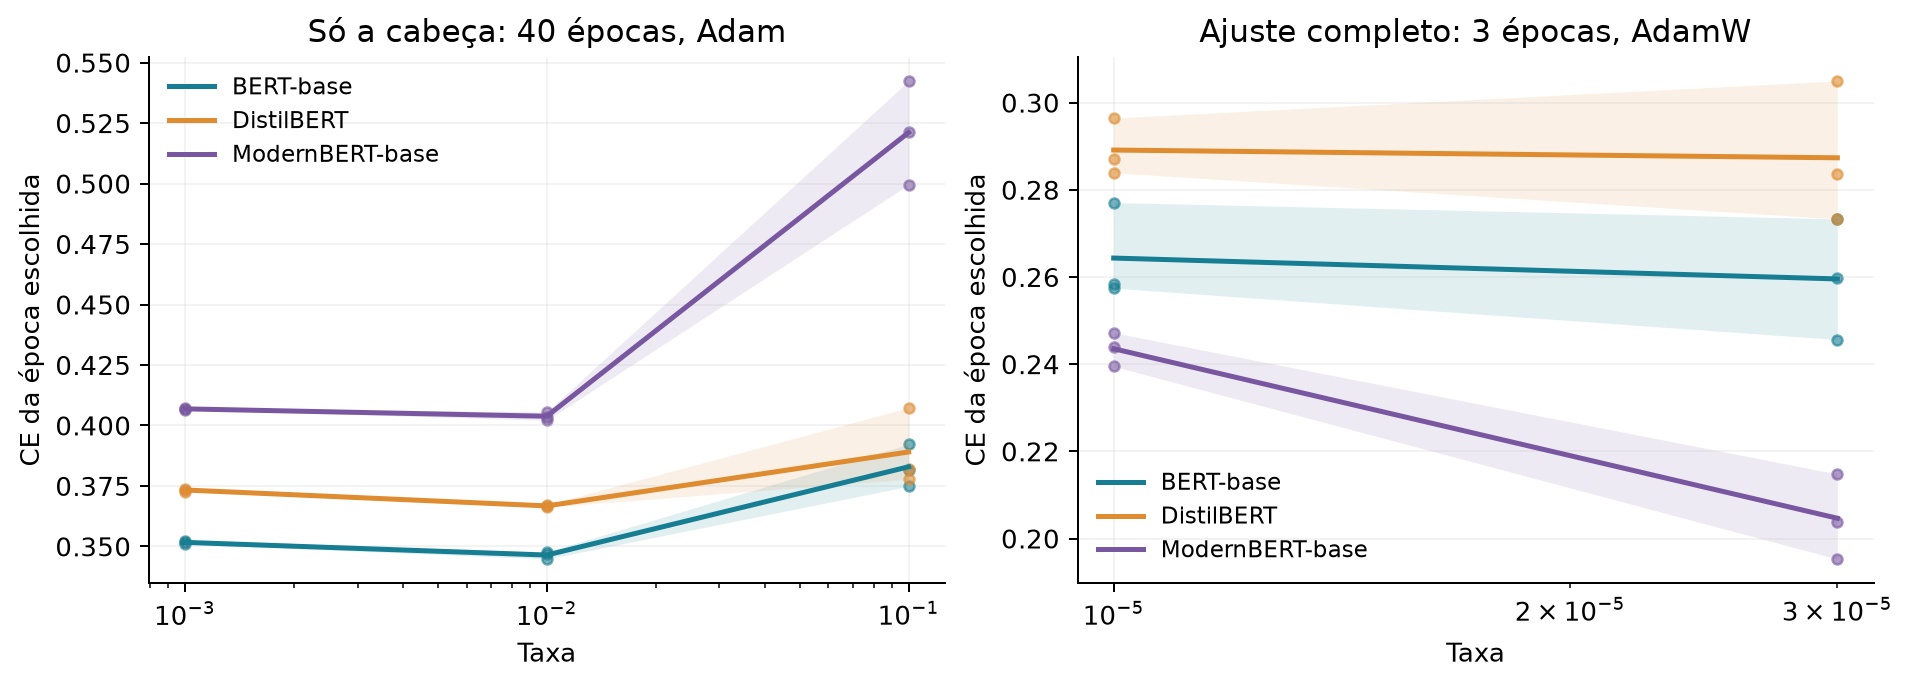

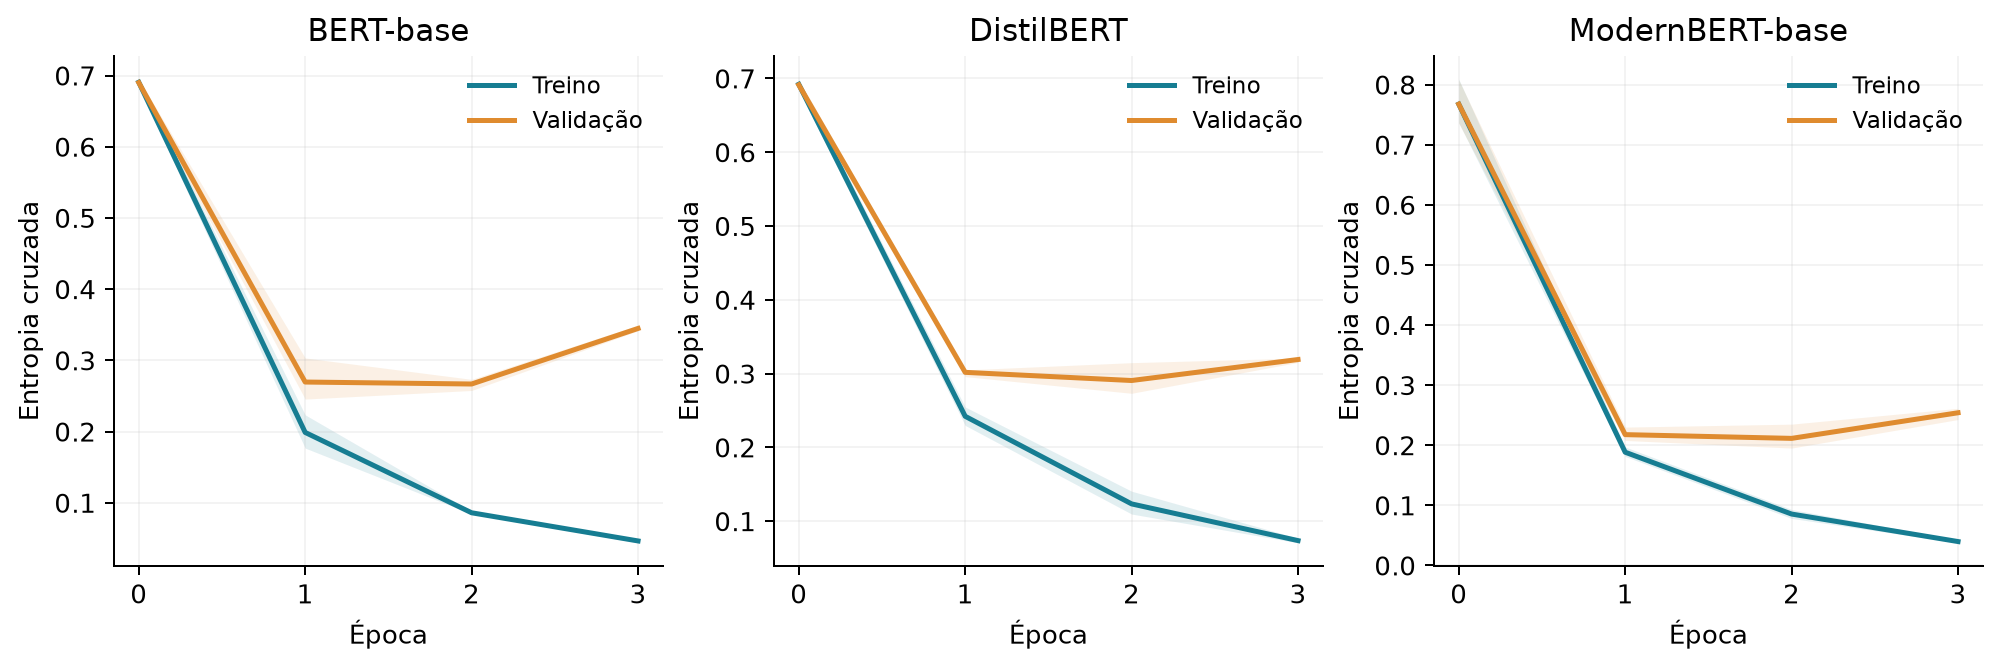

,método,taxa escolhida
0,cnn_sgd,0.30000
1,cnn_momentum,0.10000
2,cnn_adam,0.00100
3,bert_probe,0.01000
4,bert_full,0.00003
5,distilbert_probe,0.01000
6,distilbert_full,0.00003
7,modernbert_probe,0.01000
8,modernbert_full,0.00003


In [9]:
display(Image(filename=str(B / 'figures/encoder_learning_rates.png')))
display(Image(filename=str(B / 'figures/encoder_learning_curves.png')))
display(pd.DataFrame([{'método': k, 'taxa escolhida': lr} for k,lr in s['choices'].items()]))

## Tempo também é uma variável

O ajuste exclui avaliações entre épocas. No modo congelado, adicionamos a extração de vetores de treino e validação. Na inferência, contamos também o encoder congelado, para não comparar só a cabeça com um modelo completo. Downloads, carregamento e tokenização ficam fora. Os tempos refletem esta implementação no NVIDIA GB10, sem prometer a melhor eficiência de cada família.

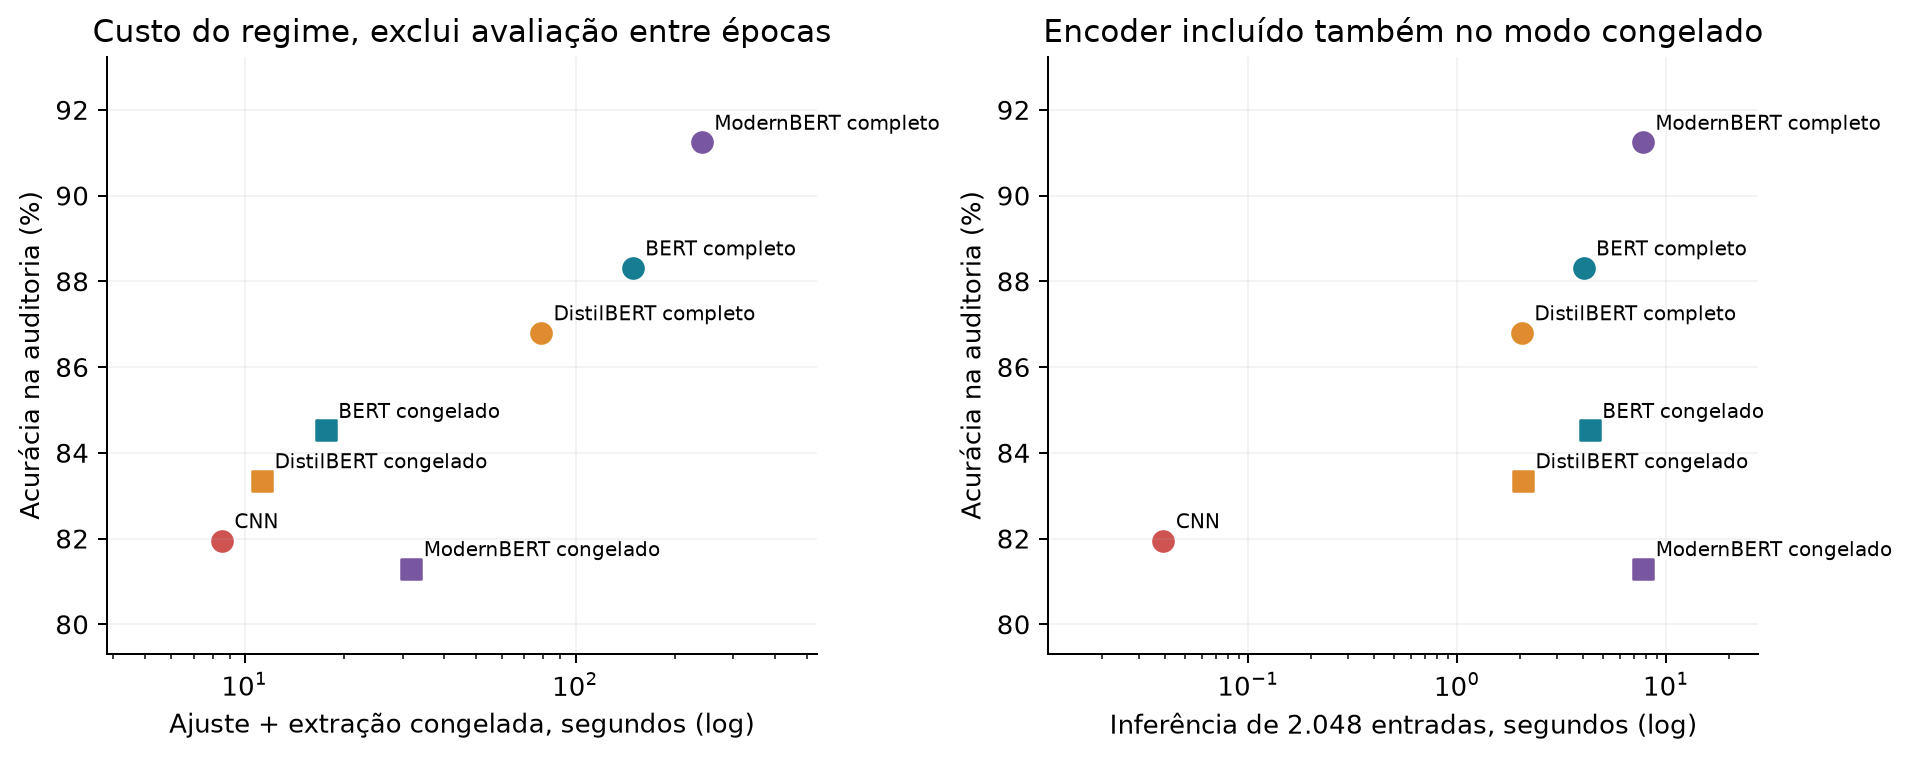

,label,fit_plus_features_seconds,total_seconds_mean,audit_end_to_end_seconds
10,BERT-base congelado,17.569470,2.904776,4.301452
11,BERT-base ajuste completo,148.934472,208.753145,4.017308
12,DistilBERT congelado,11.277107,4.074680,2.060540
13,DistilBERT ajuste completo,78.670650,109.255469,2.036070
14,ModernBERT-base congelado,31.871174,3.302351,7.751535
15,ModernBERT-base ajuste completo,240.989276,355.330136,7.719953


,tokenizador,truncadas no treino,truncadas na auditoria
0,cnn,0,0
1,bert,0,0
2,distilbert,0,0
3,modernbert,0,0


In [10]:
display(Image(filename=str(B / 'figures/cost_accuracy.png')))
display(rows[rows.group.eq('encoder')][['label','fit_plus_features_seconds','total_seconds_mean','audit_end_to_end_seconds']])
display(pd.DataFrame([{'tokenizador': k, 'truncadas no treino': r['train']['truncated_n'], 'truncadas na auditoria': r['audit']['truncated_n']} for k,r in s['tokenization'].items()]))

## Mesmos textos em modelos diferentes

Os quatro textos próprios abaixo foram definidos antes de observar suas predições e avaliados após o congelamento dos modelos. Usam sempre a semente 17, não a melhor semente da auditoria. Os rótulos pretendidos pelo autor não constituem um benchmark. As probabilidades não foram calibradas.

In [11]:
examples = read_json(B / 'synthetic_examples.json')
for e in examples['examples']:
    print(e['id'], '| intenção:', e['intended'])
    print(e['text'])
    display(pd.DataFrame([{'modelo': k, 'P(positivo)': p} for k,p in e['probabilities'].items()]))

synthetic_positive | intenção: positivo
The opening is quiet, but the patient storytelling pays off. The actors make the characters believable, the final scene is moving, and the film stays with you after the credits. I would happily watch it again.


,modelo,P(positivo)
0,cnn,0.931260
1,bert_probe,0.991234
2,bert_full,0.997019
3,distilbert_probe,0.997369
4,distilbert_full,0.982823
5,modernbert_probe,0.938089
6,modernbert_full,0.997285
7,tfidf,0.868449


synthetic_negative | intenção: negativo
The premise sounds promising, but the film wastes it. The dialogue is stiff, the characters never develop, and the final twist makes no sense. Even the attractive photography cannot rescue two hours of dull storytelling.


,modelo,P(positivo)
0,cnn,0.085838
1,bert_probe,0.001093
2,bert_full,0.000607
3,distilbert_probe,0.008910
4,distilbert_full,0.016915
5,modernbert_probe,0.003082
6,modernbert_full,0.005220
7,tfidf,0.087738


synthetic_reversal | intenção: positivo
I expected to hate this film. I was wrong. The strange opening leads to a clever story, the cast is excellent, and the ending is surprisingly warm. What looked like a disaster turned out to be a wonderful evening.


,modelo,P(positivo)
0,cnn,0.837535
1,bert_probe,0.546745
2,bert_full,0.975390
3,distilbert_probe,0.591434
4,distilbert_full,0.979511
5,modernbert_probe,0.679141
6,modernbert_full,0.987375
7,tfidf,0.654565


synthetic_mixed | intenção: negativo
Beautiful images, a talented cast, and a memorable score are all here. Unfortunately the story is a mess. The impressive first ten minutes give way to repetitive scenes, empty speeches, and an ending that feels completely unearned. I cannot recommend it.


,modelo,P(positivo)
0,cnn,0.104875
1,bert_probe,0.006555
2,bert_full,0.001988
3,distilbert_probe,0.012242
4,distilbert_full,0.067056
5,modernbert_probe,0.044594
6,modernbert_full,0.038756
7,tfidf,0.322372


## O que chega à última camada da CNN

Com dropout desligado, o logit positivo menos o negativo é uma soma exata dos máximos dos filtros vezes os pesos da saída, mais o viés. Agrupamos filtros que venceram na mesma janela. Isso descreve a leitura linear do vetor já calculado. Não é uma atribuição causal às palavras: editar o texto muda convoluções e máximos de outras posições.

In [12]:
e = examples['examples'][2]
r = e['cnn_readout']
print(e['text'])
print('Margem:', r['logit_margin'], '| soma reconstruída:', r['reconstructed_margin'])
assert abs(r['logit_margin'] - r['reconstructed_margin']) < 1e-5
display(pd.DataFrame(r['positive_windows'] + r['negative_windows']))

I expected to hate this film. I was wrong. The strange opening leads to a clever story, the cast is excellent, and the ending is surprisingly warm. What looked like a disaster turned out to be a wonderful evening.
Margem: 1.640000343322754 | soma reconstruída: 1.6400004141032696


,kernel,start,words,contribution
0,4,18,cast is excellent and,0.712318
1,3,18,cast is excellent,0.615091
2,4,20,excellent and the ending,0.403090
3,4,9,the strange opening leads,-0.395368
4,5,31,disaster turned out to be,-0.272999
5,5,4,this film i was wrong,-0.270409


## Reconstrução independente e ligação com as aulas

O verificador refaz 217 métricas a partir dos logits, confirma as escolhas de validação e o pareamento de partidas. Uma segunda avaliação na GPU reconstrói todos os 43 checkpoints. Os capítulos 6–9 de Prince explicam treinamento e seleção, o capítulo 10 trata convoluções, o 11 os resíduos e o 12 os Transformers. O double descent e o steering permanecem demonstrações próprias nos outros notebooks.

In [13]:
from importlib.util import spec_from_file_location, module_from_spec
sp = spec_from_file_location('verify_sequences', ROOT / 'verify_sequences.py')
mod = module_from_spec(sp); sp.loader.exec_module(mod)
mod.verify()
display(pd.DataFrame(read_json(ROOT / 'docs/REFERENCIAS_SEQUENCIAS.json')['references'])[['title','locators','url']].fillna(''))

{
  "status": "passed",
  "training_runs": 87,
  "cnn_runs": 42,
  "frozen_head_runs": 27,
  "full_fine_tuning_runs": 18,
  "audit_checkpoints": 43,
  "recomputed_metrics": 217,
  "max_cross_entropy_delta": 8.225653846949399e-08,
  "validation_choices": {
    "cnn_sgd": 0.3,
    "cnn_momentum": 0.1,
    "cnn_adam": 0.001,
    "bert_probe": 0.01,
    "bert_full": 3e-05,
    "distilbert_probe": 0.01,
    "distilbert_full": 3e-05,
    "modernbert_probe": 0.01,
    "modernbert_full": 3e-05
  },
  "initialization_and_batch_pairing": "passed",
  "head_initialization_policy_pairing": "passed",
  "new_audit_disjoint_from_all_prior_didactic_roles": true,
  "official_test_opened": false,
  "checkpoints_checked_locally": false
}


,title,locators,url
0,"Simon J. D. Prince, Understanding Deep Learning","Capítulos 6, 7, 8, 9, 10, 11 e 12",https://udlbook.github.io/udlbook/
1,MAE5920: Redes Convolucionais,"Páginas do arquivo 11-22, 36 e 51-52",
2,MAE5920: Transformers,"Páginas do arquivo 7-18, 21-31 e 35-38",
3,"Kim (2014), Convolutional Neural Networks for ...",,https://aclanthology.org/D14-1181/
4,"Devlin et al. (2019), BERT: Pre-training of De...",,https://aclanthology.org/N19-1423/
5,"Sanh et al. (2019), DistilBERT, a distilled ve...",,https://arxiv.org/abs/1910.01108
6,"Warner et al. (2024), Smarter, Better, Faster,...",,https://arxiv.org/abs/2412.13663
7,Answer.AI e LightOn: ModernBERT-base,,https://huggingface.co/answerdotai/ModernBERT-...
8,Transformers: implementação de ModernBERT,,https://huggingface.co/docs/transformers/model...
